*Jacek Komorowski, Politechnika Warszawska*

Notatnik omawia:

*   Przygotowanie i wytrenowanie multimodalnego modelu wyznaczającego **reprezentacje danych wizyjnych i tekstowych we wspólnej przestrzeni** reprezentacji. Rozwiązanie oparte o metodę CLIP: [Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020).
*   Zastosowanie wytrenowanego modelu do **wyszukiwania semantycznego** czyli znalezienia obrazów o podobnej zawartości semantycznej na podstawie podanego przez użytkownika obrazu bądź opisu w języku naturalnym.



#1 Przygotowanie środowiska

Sprawdzenie, czy notatnik jest uruchomiony na instancji z GPU. Sprawdzenie typu i parametrów procesora graficznego.

In [2]:
!nvidia-smi

Wed May 27 23:42:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Wykorzystywane bilioteki:
*   **PyTorch Image Models (timm)** - implementacja wielu współczesnych architektur głębokich sieci neuronowych do zastosowań wizyjnych wraz ze wstępnie wytrenowanymi wagami. Więcej info: https://huggingface.co/docs/timm/index
*   **Transformers** - moduł biblioteki Hugging Face zawierający pretrenowane modele oraz narzędzia do efektywnego dostrajania modeli głębokich sieci neuronowych (NLP, wizja komputerowa). Więcej info: https://huggingface.co/docs/transformers/index
*  **Datasets** - moduł biblioteki Hugging Face umożliwiający dostęp do wielu zbiorów danych z różnych domen (audio, wizja komputerowa, NLP). Więcej info: https://huggingface.co/docs/datasets/index
*  **TorchMetrics** - implementacje metryk wykorzystywanych do ewaluacji modeli. Więcej info: https://lightning.ai/docs/torchmetrics/stable/


In [3]:
!pip install -q datasets
!pip install -q timm
!pip install -q torchmetrics
!pip install -q wandb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 26.3 MB/s eta 0:00:00


In [4]:
from tqdm import tqdm
from PIL import Image
from typing import List, Tuple, Dict, Optional, Any
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
import torchmetrics
import timm

Klasa `Config` zawiera definiuje parametry wykorzystywanych w notatniku modeli oraz procesu uczenia.

In [5]:
@dataclass
class Config:
  image_size = 224              # Rozmiar obrazu w pikselach
  projection_dim = 256          # Rozmiar wektorowej reprezentacji (osadzenia) // embedding

  # Model językowy do ekstrakcji reprezentacji językowej
  text_model = "distilbert-base-uncased"
  max_tokens = 24               # Maksymalna długość podpisu po tokenizacji

  temperature = 0.05            # Parametr temperatury w funkcji softmax

  # Parametry data loadera
  batch_size = 64
  num_workers = 1

  # Parametry treningu modelu
  num_epochs = 3

  # Wartości stopy uczenia
  image_encoder_lr = 1e-4
  text_encoder_lr = 1e-5
  projection_head_lr = 1e-3
  weight_decay = 1e-4

#2 Pobranie zbioru danych

##2.1 Zbiór danych flickr

W notatniku wykrorzystamy zbiór danych **flickr30k** zawierający 30 tysięcy obrazów, każdy z kilkoma podpisami w języku naturalnym.


In [6]:
def load_flickr(version: str = "flickr8k") -> Dataset:
  if version == "flickr8k":
    dataset = load_dataset("jxie/flickr8k", cache_dir="./huggingface_data")
  elif version == "flickr30k":
    dataset = load_dataset("umaru97/flickr30k_train_val_test", cache_dir="./huggingface_data")
  else:
    raise NotImplemented(f"Unknown dataset version: {version}")
  return dataset

In [7]:
flickr_dataset = load_flickr(version="flickr30k")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/871 [00:00<?, ?B/s]

data/train-00000-of-00008-d81a45c0948915(…):   0%|          | 0.00/482M [00:00<?, ?B/s]

data/train-00001-of-00008-5f94761d8704b4(…):   0%|          | 0.00/493M [00:00<?, ?B/s]

data/train-00002-of-00008-d5b746892141fe(…):   0%|          | 0.00/493M [00:00<?, ?B/s]

...

data/val-00000-of-00001-3200ebe545549a22(…):   0%|          | 0.00/140M [00:00<?, ?B/s]

data/test-00000-of-00001-f4c5570f14a435e(…):   0%|          | 0.00/141M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/29000 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1014 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

In [8]:
print(flickr_dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
        num_rows: 29000
    })
    val: Dataset({
        features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
        num_rows: 1014
    })
    test: Dataset({
        features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
        num_rows: 1000
    })
})


Wyświetl losowo wybrany obraz i związane z nim podpisy.

A woman sitting on a bench next to someone wearing a hat and sitting in a wheelchair.
An elderly person in a wheelchair next to a girl sitting on a bench.
A woman is sitting on a bench next to a person in a wheelchair.
A woman puts her arm on a person sitting in a wheelchair.
Lady out with a elder person in wheelchair, in the sun.


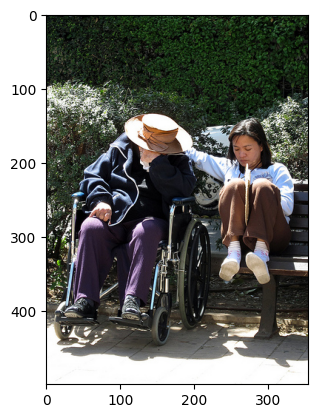

In [9]:
import random
import matplotlib.pyplot as plt

data_item = random.choice(flickr_dataset['test'])
plt.imshow(data_item['image'])
for caption in data_item['caption']:
    print(f"{caption}")


Każdy element zbioru danych flickr zawiera obraz oraz listę związanych z nim podpisów. Aby przygotować dane w formacie odpowiednim do trenowania multimodalnego modelu CLIP należy:

1.   Zamienić obrazy w formacie PIL.Image na tensory i je znormalizować.
2.   Dokonać tokenizacji podpisów (czyli zamienić tekst w języku naturalnym na listę tokenów) i przekształcić je do formatu wymaganego przez wykorzystywany model językowy (DistillBERT).


##2.2 Przygotowanie danych tekstowych

Przygotowanie tokenizatora wykorzystywanego do zamiany tekstów w języku naturalnym na listę tokenów. Model DistillBERT, podobnie jak oryginalny BERT, wykorzystuje tokenizator na poziomie podsłów oparty o metodę WordPiece ([link](https://huggingface.co/learn/nlp-course/chapter6/6?fw=pt)).

In [10]:
from transformers import DistilBertModel, DistilBertConfig, DistilBertTokenizerFast

In [11]:
tokenizer = DistilBertTokenizerFast.from_pretrained(Config.text_model)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [12]:
captions = ['Two boys', 'Small cuckoo', 'xewrfjjasderda']

for caption in captions:
  print(f'Tekst: {caption}')
  tokens = tokenizer(caption, add_special_tokens=True, padding='max_length',
                     truncation=True, max_length=Config.max_tokens)
  print(f'Wynik tokenizacji: {tokens}')
  decoded_txt = tokenizer.decode(tokens['input_ids'])
  print(f'Zdekodowane tokeny: {decoded_txt}')
  print()

Tekst: Two boys
Wynik tokenizacji: {'input_ids': [101, 2048, 3337, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}
Zdekodowane tokeny: [CLS] two boys [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]

Tekst: Small cuckoo
Wynik tokenizacji: {'input_ids': [101, 2235, 29010, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}
Zdekodowane tokeny: [CLS] small cuckoo [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]

Tekst: xewrfjjasderda
Wynik tokenizacji: {'input_ids': [101, 1060, 7974, 12881, 3501, 17386, 4063, 2850, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 

Zauważmy, że tokenizator dla modelu BERT automatycznie dodaje token `[CLS]` na początku sekwencji.
Jest to typowe zachowanie tokenizatorów dla modeli z rodziny tylko-kodet, takich jak BERT.
Wyjściowa kontekstowa reprezentacja tokenu `[CLS]` jest wykorzystywana jako **zagregowana reprezentacja całej sekwencji wejściowej**.

**Uwaga**: Aby wykorzystać reprezentacje tokenu `[CLS]` jako reprezentację całej sekwenji model językowy musi zostać odpowiednio dostrojony.

##2.2 Przygotowanie danych wizyjnych

Definicja przekształceń obrazów ze zbioru danych (normalizacja, zamiana na tensor). W trybie treningowym stosujemy urozmaicanie danych (`RandomResizedCrop`, `RandomHorizontalFlip`).
Opis nowej wersji przekształceń obrazu (v2 transforms) w PyTorch: https://pytorch.org/vision/main/transforms.html.

Nowa wersja transformacji (v2) zwraca obiekty klasy `TVTensor` będącej podklasą klasy `Tensor`. Wszystkie operacje które można wykonać na zwykłych tensorach można wykonać na obiektach klasy `TVTensor`.
Więcej informacji:
[link](https://pytorch.org/vision/main/auto_examples/transforms/plot_tv_tensors.html).


In [13]:
from torchvision.transforms import v2

def get_image_transforms(mode: str = "train"):
  if mode == "train":
    transforms = v2.Compose([
        v2.ToImage(),                         # Convert a tensor, ndarray, or PIL Image to tv_tensors.Image
        v2.ToDtype(torch.uint8, scale=True),  # Optional, most input are already uint8 at this point
        v2.RandomResizedCrop(size=(Config.image_size, Config.image_size), antialias=True),
        v2.RandomHorizontalFlip(p=0.5),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
  else:
    transforms = v2.Compose([
        v2.ToImage(),                         # Convert a tensor, ndarray, or PIL Image to tv_tensors.Image
        v2.ToDtype(torch.uint8, scale=True),  # Optional, most input are already uint8 at this point
        v2.Resize(size=(Config.image_size, Config.image_size), antialias=True),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
  return transforms


In [14]:
image = flickr_dataset['train'][0]['image']
transforms = get_image_transforms('train')
x = transforms(image)
print(type(x))
print(x.shape)

<class 'torchvision.tv_tensors._image.Image'>
torch.Size([3, 224, 224])


Definicja obiektu klasy `Dataset` dostarczającej dane w formacie odpowiednim do trenowania multimodalnego modelu CLIP.
Metoda `__getitem__` zwraca słownik zawierający pola:

*   **image** - obraz przekształcony na tensor i znormalizowany
*   **tokenized_caption** - wybrany losowo podpis w postaci słownika z polami `input_ids` (tensor z identyfikatorami tokenów) and `attention_mask` (tensor z maską binarną, gdzie zera odpowiadają tokenom `[PAD]`)
*   **caption** - podpis w języku naturalnym


In [15]:
class CLIPDataset(Dataset):
  def __init__(self, dataset: Dataset, tokenizer, image_transforms):
    # dataset: Flickr dataset
    self.dataset = dataset
    self.tokenizer = tokenizer
    self.image_transforms = image_transforms

    # Tokenizacja podpisów
    self.raw_captions = []
    self.tokenized_captions = []
    for data_item in tqdm(dataset, desc="Tokenizacja tekstu..."):
      self.raw_captions.append(data_item['caption'])
      temp = tokenizer(data_item['caption'], add_special_tokens=True, padding='max_length',
                       truncation=True, max_length=Config.max_tokens, return_tensors='pt')
      self.tokenized_captions.append(temp)

  def __getitem__(self, idx) -> Dict[str, Any]:
    image = self.dataset[idx]['image']

    # Zastosuj transformacje, zamień na tensor i znormalizuj
    image = self.image_transforms(image)

    # Wybierz losowo jeden podpis
    k = random.randrange(len(self.tokenized_captions[idx])) # one sample can be described by multiple texts/sentences, k is random index of the sentence 0 <= k <= ...
    input_ids = self.tokenized_captions[idx]['input_ids'][k]
    attention_mask = self.tokenized_captions[idx]['attention_mask'][k]
    data_item = {
        'image': image,
        'input_ids': input_ids,
        'attention_mask': attention_mask,
        'caption': self.raw_captions[idx][k]
        }
    return data_item

  def __len__(self) -> int:
    return len(self.dataset)

Utworzenie zbioru danych treningowych i walidacyjnych.

In [16]:
training_dataset = CLIPDataset(flickr_dataset['train'], tokenizer, get_image_transforms(mode="train"))
val_dataset = CLIPDataset(flickr_dataset['val'], tokenizer, get_image_transforms(mode="val"))

Tokenizacja tekstu...: 100%|██████████| 1014/1014 [00:03<00:00, 284.28it/s]


Wyświetlenie losowo wybranych przykładów ze zbioru danych.

In [17]:
for i in range(3):
  x = random.choice(training_dataset)
  print(f"{x['caption']=}")
  print(f"{x['input_ids']=}")
  print(f"{x['attention_mask']=}")
  print(f"{x['image'].shape=}")
  print()

x['caption']='A woman pushes a cleaning machine while walking on a brick pathway beside a minivan yellow cab.'
x['input_ids']=tensor([  101,  1037,  2450, 13956,  1037,  9344,  3698,  2096,  3788,  2006,
         1037,  5318, 12732,  3875,  1037,  7163,  6212,  3756,  9298,  1012,
          102,     0,     0,     0])
x['attention_mask']=tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0])
x['image'].shape=torch.Size([3, 224, 224])

x['caption']='Two dancers are giving a performance at public function.'
x['input_ids']=tensor([  101,  2048, 10487,  2024,  3228,  1037,  2836,  2012,  2270,  3853,
         1012,   102,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0])
x['attention_mask']=tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
x['image'].shape=torch.Size([3, 224, 224])

x['caption']="A man in a chef's jacket is seated at a white table and writing in a book."
x['input_ids']=tensor

#3 Architektura modelu CLIP

##3.1 Głowica projekcyna

**ZADANIE**

Uzupełnij kod klasy `ProjectionHead` implementującej głowicę projekcyjną przekształcającą wejściwy wsad $x$ o rozmiarze `(batch_size, embedding_dim)` do wyjściowej znormalizowanej reprezentacji $z$ o rozmiarze`(batch_size, projection_dim)`:
1.   Wykorzystaj pojedynczą warstwę liniowę (nn.Linear) z parametrem `bias=False`.
2.   Następnie wykorzystaj funkcję `nn.functional.normalize` aby znormalizować zwracany tensor.

$$y = x A^T$$
$$z = \frac{y}{||y||_2}$$


In [18]:
class ProjectionHead(nn.Module):
  def __init__(self, embedding_dim: int, projection_dim: int):
    super().__init__()
    self.projection_dim = projection_dim

    # *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
    self.projection = nn.Linear(in_features=embedding_dim, out_features=projection_dim, bias=False)
    # *** KONIEC KODU DO UZUPEŁNIENIA ***

  def forward(self, x: Tensor) -> Tensor:
    # *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
    y = self.projection(x)  # nn.Linear layer performs 'combination' of (neuron inputs) 'x' and (layer weights) 'A.T' - A is transposed to perform matrix multiplication
    z = nn.functional.normalize(y)
    # *** KONIEC KODU DO UZUPEŁNIENIA ***
    return z

Sprawdzenie klasy `ProjectionHead`


In [19]:
d_in = 128
d_out = 64
batch_size = 32
proj_head = ProjectionHead(d_in, d_out)
n_params = sum([p.numel() for p in proj_head.parameters()])
assert len(list(proj_head.parameters())) == 1, f"Głowica projekcyjna powinna zawierać tylko pojedyczą warstwę liniową"
assert n_params == d_in * d_out, f"Głowica projekcyjna powinna zawierać tylko pojedynczą warstwę liniową z parametrem bias=False"

assert isinstance(proj_head, nn.Module)
x = torch.rand((batch_size, d_in))
print(f"{x.shape=}")
z = proj_head(x)
print(f"{z.shape=}")

assert z.shape == (batch_size, d_out), f"Nieprawidłowy rozmiar tensora z: {z}"
assert z.norm(dim=1).isclose(torch.tensor(1.)).all(), f"Znormalizuj reprezentację wejściową: {z.norm(dim=1)}"

x.shape=torch.Size([32, 128])
z.shape=torch.Size([32, 64])



##3.2 Koder danych tekstowych

Do ekstrakcji reprezentacji sekwencji tektowych wykorzystamy pretrenowany model językowy DistillBERT (https://huggingface.co/docs/transformers/model_doc/distilbert).
Jest to niewielki model językowy z rodziny tylko-koder (oparty o dwukierunkowy transformer) wytrenowany poprzez destylację wiedzy
 z pełnego modelu BERT. Artykuł opisujący architekturę i sposób trenowania modelu BERT ([link](https://arxiv.org/abs/1810.04805)).

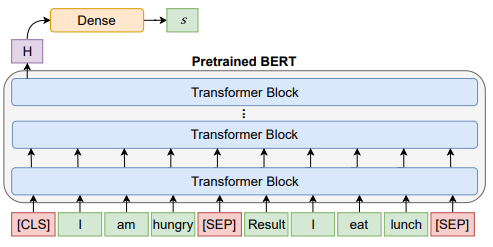

In [20]:
class TextEncoder(nn.Module):
  def __init__(self) -> None:
    super().__init__()
    self.backbone = DistilBertModel.from_pretrained(Config.text_model)
    self.embedding_dim = self.backbone.config.dim
    # Jak reprezentację całej sekwencji brana jest reprezentacja tokenu [CLS] na pozycji 0
    self.CLS_token_idx = 0
    self.projection = ProjectionHead(embedding_dim=self.embedding_dim, projection_dim=Config.projection_dim)

  def forward(self, input_ids: Tensor, attention_mask: Tensor) -> Tensor:
    x = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
    last_hidden_state = x.last_hidden_state
    # last_hidden_state is (batch_size, sequence_length, embedding_dim) tensor
    x = last_hidden_state[:, self.CLS_token_idx, :]
    # x is (batch_size, embedding_dim) tensor
    x = self.projection(x)
    # x is (batch_size, projection_dim) tensor
    return x

##3.3 Koder danych obrazowych

Jako koder danych obrazowych wykorzystamy architekturę ResNet50 z biblioteki timm.

**ZADANIE**

Uzupełnij kod klasy `ImageEncoder`

1.   W metodzie `__init__` utwórz liniową głowicę projekcyjną (klasa `ProjectionHead`) rzutującą wektor reprezentacji o rozmiarze `self.embedding_dim` na wektor o rozmiarze `self.projection_dim`.
2.   Napisz kod metody `forward` - wyznacz reprezentację obrazów przy pomocy sieci bazowej (`self.backbone`) a następnie rzutuj ją do wspólnej przestrzeni reprezentacji przy wykorzystaniu głowicy projekcyjnej (`self.projection`). Metoda forward na wejściu otrzymuje wsad obrazów o wymiarze `(batch_size, 3, image_size, image_size)`. Na wyjściu zwraca tensor `(batch_size, projection_dim)`.



In [21]:
class ImageEncoder(nn.Module):
  def __init__(self) -> None:
    super().__init__()
    # Create the network without the last classification layer (num_classes=0)
    self.backbone = timm.create_model('resnet50', pretrained=True,
                                      num_classes=0)
    self.embedding_dim = self.backbone.feature_info[-1]['num_chs']

    # *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
    self.projection = ProjectionHead(embedding_dim=self.embedding_dim, projection_dim=Config.projection_dim)
    # *** KONIEC KODU DO UZUPEŁNIENIA ***

  def forward(self, x: Tensor) -> Tensor:

    # *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
    x = self.backbone(x)
    # x is (batch_size, embedding_dim) tensor
    x = self.projection(x)
    # x is (batch_size, projection_dim) tensor
    # *** KONIEC KODU DO UZUPEŁNIENIA ***

    return x


Sprawdzenie klasy `ImageEncoder`.

In [22]:
img_encoder = ImageEncoder()
batch_size = 10
x = torch.rand((batch_size, 3, Config.image_size, Config.image_size))
print(x.shape)
y = img_encoder(x)
print(y.shape)

assert y.ndim == 2
assert y.shape[0] == batch_size
assert y.shape[1] == Config.projection_dim

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

torch.Size([10, 3, 224, 224])
torch.Size([10, 256])


In [23]:
def count_parameters(model: nn.Module) -> Tuple[int, int]:
  trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
  all_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
  return trainable_params, all_params

**Definicja modelu CLIP.** Metoda `forward` na wejściu otrzymuje wsad złożony z par obrazów i podpisów po tokenizacji. Na wyjściu zwróci parę tensorów:
*   jeden o wymiarach (batch_size, projection_dim) zawierający reprezentacje obrazów we wsadzie
*   drugi o wymiarach (batch_size, projection_dim) zawierający reprezentacje podpisów pod obrazami

In [24]:
class CLIPModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.text_encoder = TextEncoder()
    self.image_encoder = ImageEncoder()

  def forward(self, batch):
    text_embeddings = self.text_encoder(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'])
    image_embeddings = self.image_encoder(batch["image"])
    return text_embeddings, image_embeddings

  def print_info(self):
    print(f"Text embedding dimensionality: {self.text_encoder.embedding_dim}   projected: {self.text_encoder.projection.projection_dim}")
    print(f"Image embedding dimensionality: {self.image_encoder.embedding_dim}   projected: {self.image_encoder.projection.projection_dim}")
    nt, na = count_parameters(self.text_encoder)
    print(f"Text encoder parameters (trainable/all): {nt} / {na}")
    nt, na = count_parameters(self.image_encoder)
    print(f"Image encoder parameters (trainable/all): {nt} / {na}")
    nt, na = count_parameters(self)
    print(f"All parameters (trainable/all): {nt} / {na}")


Definicja kontrastywnej funkcji straty z temperaturą wykorzystywanej przy uczeniu modelu CLIP.

In [25]:
def CLIP_loss(text_embeddings: Tensor, image_embeddings: Tensor) -> Tuple[Tensor, float, float]:
    assert text_embeddings.shape == image_embeddings.shape
    assert text_embeddings.device == image_embeddings.device

    n = len(text_embeddings)        # Batch size

    # Create labels tensor = tensor([0, 1,..., n-1])
    labels = torch.arange(n).to(text_embeddings.device)

    logits = (text_embeddings @ image_embeddings.T) / Config.temperature
    img_acc, cap_acc = calc_metrics(logits)

    # Calculate cross entropy losses along axis 0 and 1
    loss_i = F.cross_entropy(logits.transpose(0, 1), labels, reduction="mean")
    loss_t = F.cross_entropy(logits, labels, reduction="mean")

    # Calculate the final loss
    loss = (loss_i + loss_t) / 2

    return loss, img_acc, cap_acc

@torch.no_grad
def calc_metrics(logits: torch.Tensor) -> Tuple[float, float]:
    y = torch.arange(len(logits)).to(logits)
    img2cap_match_idx = logits.argmax(dim=1)
    cap2img_match_idx = logits.argmax(dim=0)

    img_acc = (img2cap_match_idx == y).float().mean().item()
    cap_acc = (cap2img_match_idx == y).float().mean().item()

    return img_acc, cap_acc

#4 Trenowanie modelu

Definicja dataloaderów tworzących wsady treningowe i walidacyjne.

In [26]:
dataloader = {
    'train': DataLoader(training_dataset, batch_size=Config.batch_size, num_workers=Config.num_workers, shuffle=True),
    'val': DataLoader(val_dataset, batch_size=Config.batch_size, num_workers=Config.num_workers)
}


Utworzenie instancji modelu klasy CLIPModel(). Utworzenie optymalizatora parametrów modelu - każda podsieć w modelu (bazowa sieć ekstrakcji cech wizyjnych, bazowa sieć ekstakcji cech z danych tekstowych, głowice projekcyjne) jest uczona z inną stopą uczenia.

In [27]:
clip_model = CLIPModel()
clip_model.print_info()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clip_model.to(device)

params = [
  {"params": clip_model.text_encoder.backbone.parameters(), "lr": Config.text_encoder_lr},
  {"params": clip_model.image_encoder.backbone.parameters(), "lr": Config.image_encoder_lr},
  {"params": clip_model.text_encoder.projection.parameters(), "lr": Config.projection_head_lr, "weight_decay": Config.weight_decay},
  {"params": clip_model.image_encoder.projection.parameters(), "lr": Config.projection_head_lr, "weight_decay": Config.weight_decay},
]
optimizer = torch.optim.AdamW(params, weight_decay=0.)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Text embedding dimensionality: 768   projected: 256
Image embedding dimensionality: 2048   projected: 256
Text encoder parameters (trainable/all): 66559488 / 66559488
Image encoder parameters (trainable/all): 24032320 / 24032320
All parameters (trainable/all): 90591808 / 90591808


Pętla uczenia modelu. Każda epoka składa się z fazy treningu oraz walidacji.
Oczekiwany czas treningu przez 3 epoki z wykorzystaniem T4 GPU to około 18 minut.
W tym czasie można zapoznać się z:
   * artykułem na blogu OpenAI opisującym metodę CLIP: [link](https://openai.com/research/clip)
   * artykułem w serwisie Hugging Face opisującym ulepszoną metodę wyznaczania wspólnej reprezentacji wizyjno-językowej SigLIP 2: [link](https://huggingface.co/blog/siglip2)

In [28]:
from tqdm import tqdm

# Per-batch metrics
loss_metric = torchmetrics.aggregation.MeanMetric()
img_acc_metric = torchmetrics.aggregation.MeanMetric()
cap_acc_metric = torchmetrics.aggregation.MeanMetric()

for epoch in range(Config.num_epochs):
  for phase in ['train', 'val']:
    loss_metric.reset()
    img_acc_metric.reset()
    cap_acc_metric.reset()

    if phase == 'train':
      clip_model.train()
    else:
      clip_model.eval()

    for batch in tqdm(dataloader[phase]):
      batch['image'] = batch['image'].to(device)
      batch['input_ids'] = batch['input_ids'].to(device)
      batch['attention_mask'] = batch['attention_mask'].to(device)
      with torch.set_grad_enabled(phase=='train'):
        text_embeddings, image_embeddings = clip_model(batch)
        loss, img_acc, cap_acc = CLIP_loss(text_embeddings, image_embeddings)

      loss_metric.update(loss.item())
      img_acc_metric.update(img_acc)
      cap_acc_metric.update(cap_acc)

      # Backward pass and optimization
      if phase == 'train':

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if phase == 'train':
      print(f"({phase})  epoch: {epoch+1}/{Config.num_epochs}  Loss: {loss_metric.compute():.3f}")
    else:
      print(f"({phase})  epoch: {epoch+1}/{Config.num_epochs}  Loss: {loss_metric.compute():.3f}  img2text acc: {img_acc_metric.compute():.3f}  txt2img acc: {cap_acc_metric.compute():.3f}")


100%|██████████| 454/454 [06:44<00:00,  1.12it/s]


(train)  epoch: 1/3  Loss: 2.092


100%|██████████| 16/16 [00:07<00:00,  2.22it/s]


(val)  epoch: 1/3  Loss: 1.503  img2text acc: 0.564  txt2img acc: 0.547


100%|██████████| 454/454 [06:57<00:00,  1.09it/s]


...

(val)  epoch: 2/3  Loss: 1.245  img2text acc: 0.629  txt2img acc: 0.627


100%|██████████| 454/454 [06:58<00:00,  1.09it/s]


(train)  epoch: 3/3  Loss: 1.246


100%|██████████| 16/16 [00:07<00:00,  2.07it/s]

(val)  epoch: 3/3  Loss: 1.152  img2text acc: 0.656  txt2img acc: 0.656


Zwolnienie pamięci na GPU.

In [29]:
import gc

del batch
del loss
del text_embeddings
del image_embeddings
del optimizer
gc.collect()
torch.cuda.empty_cache()
!nvidia-smi

Thu May 28 00:08:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   75C    P0             44W /   70W |    1261MiB /  15360MiB |     70%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

#5 Wykorzystanie wytrenowanego modelu


Funkcje pomocnicze do konwersji pojedycznego elementu (obrazu, tekstu i pary obrazu z tekstem) na jednoelementowy wsad.

Modele sieci neuronowych w PyTorch (obiekty klasy `torch.nn.Module`) wymagają na wejściu wsadów. Jeśli chcemy przetworzyć pojedynczy element ze zbioru danych, musimy zamienić go na jednoelementowy wsad.

In [30]:
def make_batch(data_item, device):
  # Convert a data item to one-element batch and move to the device
  data_item['image'] = data_item['image'].unsqueeze(0).to(device)
  data_item['input_ids'] = data_item['input_ids'].unsqueeze(0).to(device)
  data_item['attention_mask'] = data_item['attention_mask'].unsqueeze(0).to(device)
  data_item['caption'] = [data_item['caption']]
  return data_item

**ZADANIE**

Sprawdź działanie wytrenowanego modelu `clip_model`.

1.   Wyznacz reprezentacje dwóch losowo wybranych  elementów z testowego zbioru danych (wsady `b1` i `b2`).
2.   Oblicz podobieństwo kosinusowe między:
  *   Reprezentacją obrazu z pierwszego elementu i reprezentacjami tekstu z pierwszego i drugiego elementu
  *   Reprezentacją obrazu z drugiego elementu i reprezentacjami tekstu z pierwszego i drugiego elementu
  
Reprezentacje obrazu i tekstu z tego samego elementu zbioru danych powinny być bardziej podobne (w sensie podobieństwa kosinusowego) niż reprezentacje obrazu i tekstu dla różnych elementów.




In [31]:
test_dataset = CLIPDataset(flickr_dataset['test'], tokenizer, get_image_transforms(mode="test"))

Tokenizacja tekstu...: 100%|██████████| 1000/1000 [00:03<00:00, 276.99it/s]


In [32]:
clip_model.eval()

e1 = test_dataset[9]
e2 = test_dataset[140]
b1 = make_batch(e1, device)
b2 = make_batch(e2, device)

# *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
txt_embedding_1, img_embedding_1 = clip_model(b1)
txt_embedding_2, img_embedding_2 = clip_model(b2)

cos_sim_i1_t1 = F.cosine_similarity(img_embedding_1, txt_embedding_1, dim=1)
cos_sim_i1_t2 = F.cosine_similarity(img_embedding_1, txt_embedding_2, dim=1)

print(f"Cosine similarity between - representation of 1st image and 1st text {cos_sim_i1_t1}")
print(f"Cosine similarity between - representation of 1st image and 2nd text {cos_sim_i1_t2}")

cos_sim_i2_t1 = F.cosine_similarity(img_embedding_2, txt_embedding_1, dim=1)
cos_sim_i2_t2 = F.cosine_similarity(img_embedding_2, txt_embedding_2, dim=1)

print(f"Cosine similarity between - representation of 2nd image and 1st text {cos_sim_i2_t1}")
print(f"Cosine similarity between - representation of 2nd image and 2nd text {cos_sim_i2_t2}")

# *** KONIEC KODU DO UZUPEŁNIENIA ***


Cosine similarity between - representation of 1st image and 1st text tensor([0.4967], device='cuda:0', grad_fn=<SumBackward1>)
Cosine similarity between - representation of 1st image and 2nd text tensor([0.1955], device='cuda:0', grad_fn=<SumBackward1>)
Cosine similarity between - representation of 2nd image and 1st text tensor([-0.0661], device='cuda:0', grad_fn=<SumBackward1>)
Cosine similarity between - representation of 2nd image and 2nd text tensor([0.6326], device='cuda:0', grad_fn=<SumBackward1>)


##5.1 Wyszukiwanie podobnych obrazów

W tej części notatnika wykorzystamy wytrenowany model `clip_model` do wyszukiwania obrazów o podobnej zawartości semantycznej (*semantic image search*).

Pobierzemy przykładowy obraz z Internetu i będziemy szukali obrazów do niego podobnych w testowym zbiorze danych (`test_dataset`).

Image tensor shape: torch.Size([1, 3, 224, 224])
Image embedding shape: torch.Size([256])


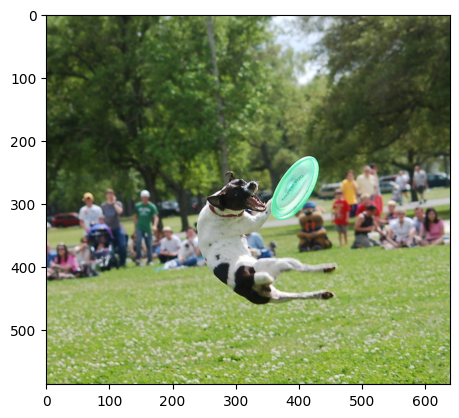

In [33]:
import requests

url = 'http://farm3.staticflickr.com/2305/2381606562_e87d706d5f_z.jpg'
input_image = Image.open(requests.get(url, stream=True).raw)
plt.imshow(input_image)

transform_to_tensor = get_image_transforms('test')
input_img_tensor = transform_to_tensor(input_image)
input_img_batch = input_img_tensor.unsqueeze(0).to(device)
print(f"Image tensor shape: {input_img_batch.shape}")

clip_model.eval()
input_img_embedding = clip_model.image_encoder(input_img_batch)
input_img_embedding = input_img_embedding.squeeze(0)    # Remove the batch dimension
print(f"Image embedding shape: {input_img_embedding.shape}")

**ZADANIE**

Uzupełnij kod funkcji obliczającej reprezentacje wszystkich obrazów w zbiorze danych za pomocą wytrenowanego modelu klasy `CLIPModel`.
Model domyślnie przetwarza pary złożone z obrazów i odpowiadających ich podpisów.
Aby wyznaczyć reprezentacje samych obrazów wykorzystaj podsieć ekstrakcji danych wizyjnych (`model.image_encoder`).

In [34]:
@torch.no_grad
def compute_image_embeddings(model: CLIPModel, dataset: Dataset) -> Tensor:
  # Compute embeddings for all images in the dataset
  model.eval()
  embeddings = torch.zeros((len(dataset), model.image_encoder.projection.projection_dim), device=device)

  for ndx, data_item in enumerate(tqdm(dataset)):
    batch = make_batch(data_item, device)

    # *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
    embeddings[ndx] = model.image_encoder(batch["image"]).squeeze()

    # *** KONIEC KODU DO UZUPEŁNIENIA ***

  assert embeddings.shape == (len(dataset), model.image_encoder.projection.projection_dim)
  return embeddings


Sprawdzenie działenia funkcji `compute_image_embeddings` i wyznaczenie reprezentacji wszystkich obrazów ze zbioru testowego.

In [35]:
image_embeddings = compute_image_embeddings(clip_model, test_dataset)
assert image_embeddings.shape == (len(test_dataset), clip_model.image_encoder.projection.projection_dim)

print()
print(image_embeddings.shape)


100%|██████████| 1000/1000 [00:11<00:00, 84.29it/s]


torch.Size([1000, 256])


**ZADANIE**

Uzupełnij kod funkcji znajdującej dla danego wektora reprezentacji `query_embedding` $k$ najbliższych sąsiadów w macierzy reprezentacji (`dataset_embeddings`) wyznaczonej dla wszystkich elementów zbioru danych.

Funkcja `find_nn`:

*   Na wejściu otrzymuje wektor query_embedding o wymiarze `(projection_dim,)` oraz tensor zawierający reprezentacje elementów zbioru danych wśród których szukamy najbliższych sąsiadów `dataset_embeddings` o wymiarze `(dataset_size, projection_dim)`.
*   Na wyjściu musi zwrócić dwie listy zawierające:
   *   listę indeksów $k$ wierszy `dataset_embeddings` najbardziej podobnych do `query_embedding` (w sensie podobieństwa kosinusowego).
   *   listę wartości podobieństwa kosinusowego między `query_embedding` a znalezionymi $k$ najbliższymi sąsiadami


In [36]:
def find_nn(query_embedding: Tensor, dataset_embeddings: Tensor, k: int) -> Tuple[List[int], List[float]]:
    # Return indices of k embeddings closest to the query embedding
    # query_embedding: tensor (projection_dim, )
    # dataset_embeddings: tensor (dataset_size, projection_dim)

    assert query_embedding.ndim == 1
    assert dataset_embeddings.ndim == 2
    assert query_embedding.shape[0] == dataset_embeddings.shape[1]

    # *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
    # Compute the cosine similarity between the queyr_embedding and embeddings of test set images
    sim = F.cosine_similarity(query_embedding.unsqueeze(0), dataset_embeddings, dim=1)

    # sim is (dataset_size,) tensor

    # Find indices of k items the most similar to query_embedding
    sim, nn_idx = torch.topk(sim, k)

    # *** KONIEC KODU DO UZUPEŁNIENIA ***

    return nn_idx.tolist(), sim.tolist()


Sprawdzenie działania funkacji `find_nn`.

In [37]:
n = 101
test_img_embedding = image_embeddings[n]

k = 5
nn_idx, sim = find_nn(test_img_embedding, image_embeddings, k=k)
print(nn_idx)
print(sim)

assert len(nn_idx) == k
assert len(sim) == k

assert nn_idx[0] == n, f"Element o indeksie {n} powinien być zwrócony jako pierwszy - jako najbardziej podobny do siebie samego"
assert sim[0] > .9999

assert all([sim[i] - sim[i+1] > 0 for i in range(k-1)]), "Zwrócone podobieństwa muszą być w malejącej kolejności"

[101, 866, 657, 340, 654]
[1.0000001192092896, 0.9487659931182861, 0.9140814542770386, 0.7422825694084167, 0.7169132232666016]


Wyszukanie i wyświetlenie pięciu najbardziej podobnych obrazów dla  obrazu o wektorze reprezentacji `input_img_embedding`.

5 najbliższych sądiadów w przestrzeni reprezentacji: [281, 285, 1, 162, 232]


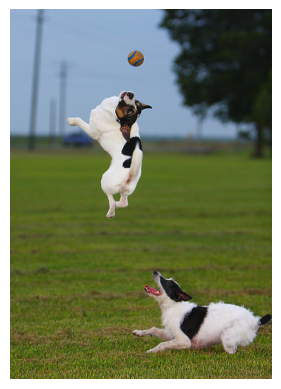

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.813 
['The two dogs, one of which is leaping in the air, are chasing a ball outdoors.', 'One dog leaps to catch a softball while another looks on.', 'Two small dogs pursuing a ball across a grassy field.', 'Two dogs play catch with a ball in a field.', 'Two dogs jump for a ball on a green field.']


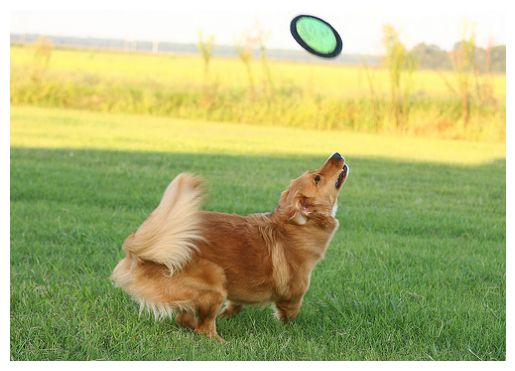

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.762 
['A brown dog waits for the Frisbee to come down before catching it.', 'Dog standing in grass playing with green flying disc', 'A brown dog about to catch a green Frisbee.', 'A dog gets ready to catch a Frisbee.', 'A dog catching a Frisbee.']


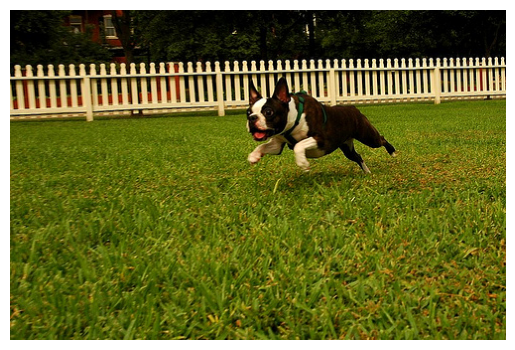

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.696 
['A black and white dog is running in a grassy garden surrounded by a white fence.', 'A Boston Terrier is running on lush green grass in front of a white fence.', 'A black and white dog is running through the grass.', 'A dog runs on the green grass near a wooden fence.', 'A Boston terrier is running in the grass.']


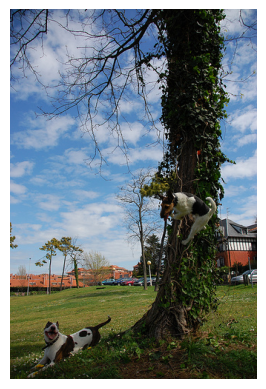

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.666 
['A dog jumps by a tree while another lays on the ground.', 'A dog leaps high in the air while another watches.', 'A dog chases another by a tree.', 'Two dogs are playing outside.', 'Two dogs play by a tree.']


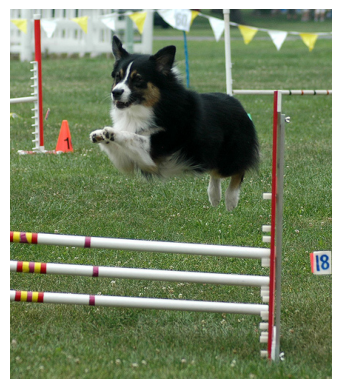

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.665 
['A dog jumping over high jump poles at show.', 'A black and white dog jumps over a hurdle.', 'A small dog jumps over a striped gate.', 'A dog jumps over an obstacle outside.', 'A small dog leaps a barrier.']


In [38]:
k = 5
nn_idx, dist = find_nn(input_img_embedding, image_embeddings, k=k)

print(f"{k} najbliższych sądiadów w przestrzeni reprezentacji: {nn_idx}")

for idx, d in zip(nn_idx, dist):
  #item = test_dataset[idx]
  img = test_dataset.dataset[idx]['image']
  plt.imshow(img)
  plt.axis("off")
  plt.show()
  print(f"Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: {d:0.3f} ")
  print(test_dataset.raw_captions[idx])

##5.2 Wyszukiwanie obrazów na podstawie tekstu w języku naturalnym

W tej części notatnika wykorzystamy wytrenowany model `clip_model` (obiekt klasy klasy `CLIPModel`) do wyszukiwania obrazów na podstawie tekstu w języku naturalnym.

1.   Wyznacz reprezentację podanego tesktu w języku naturalnym przy wykorzystaniu wytrenowanego modelu `clip_model`.
2.   Wyznacz reprezentacje wszystkich obrazów w zbiorze danych do przeszukania.
3.   Znajdź obraz w zbiorze danych o reprezentacji najbardziej podobnej (w sensie podobieństwa kosinusowego) do reprezentacji danego tekstu.

Model `CLIPModel` domyślnie przetwarza pary złożone z obrazów i odpowiadających ich podpisów. Aby wyznaczyć reprezentacje jednego rodzaju danych należy wykorzystać odpowiednią podsieć ekstrakcji cech (`clip_model.image_encoder` lub `clip_model.text_encoder`).


In [39]:
#text_prompt = "a child looking at the sky"
text_prompt = "a man and a red car"

# Encode the text prompt and compute its embedding
# See how the text is tokenized inside the CLIPDataset class
tokenized_prompt = tokenizer(text_prompt, add_special_tokens=True, padding='max_length', truncation=True, max_length=Config.max_tokens, return_tensors='pt')
print(tokenized_prompt)

clip_model.eval()
text_prompt_embedding = clip_model.text_encoder(tokenized_prompt['input_ids'].to(device), tokenized_prompt['attention_mask'].to(device))
text_prompt_embedding = text_prompt_embedding.squeeze(0)   # Remove the batch dimension

print(f"Text embedding shape: {text_prompt_embedding.shape}")


{'input_ids': tensor([[ 101, 1037, 2158, 1998, 1037, 2417, 2482,  102,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])}
Text embedding shape: torch.Size([256])


5 nearest neighbours: [514, 241, 515, 735, 589]


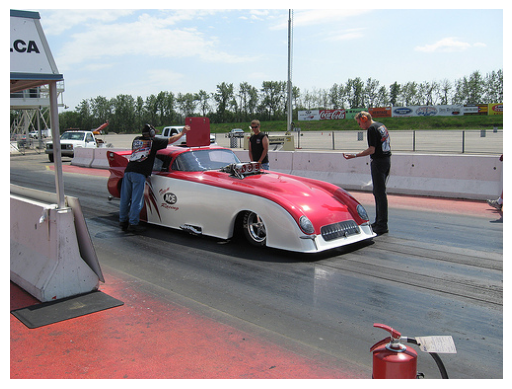

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.791 
['A drag race car being worked on by 3 people on a track', 'Three men are examining a red and white race car.', 'Three men standing around a car on a racetrack.', 'Several men standing around an antique race car', 'Pit crew working on a race car.']


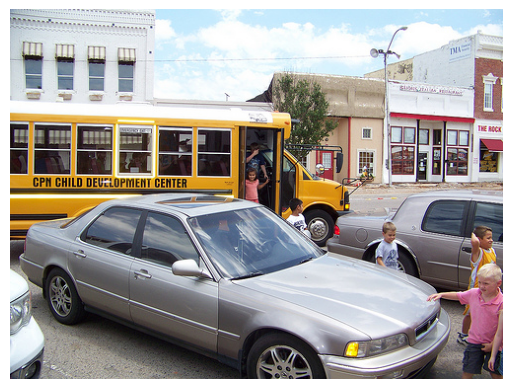

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.667 
['The school bus is unloading children near the parked cars.', 'Small children are getting off a school bus.', 'Parked cars with a school bus behind them.', 'Kids getting off a yellow school bus.', 'The children are getting off the bus.']


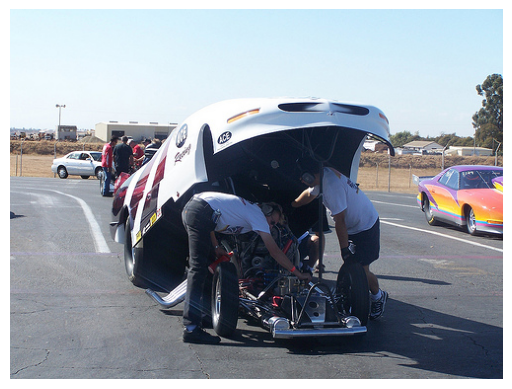

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.642 
["Two men wearing earmuffs inspect a racing car's engine on an asphalt track.", 'Two men work under the hood of a white race car.', 'Two mechanics are fixing a racing white car.', 'Two mechanics working on a drag racing car.', 'Two men under the body of a drag car.']


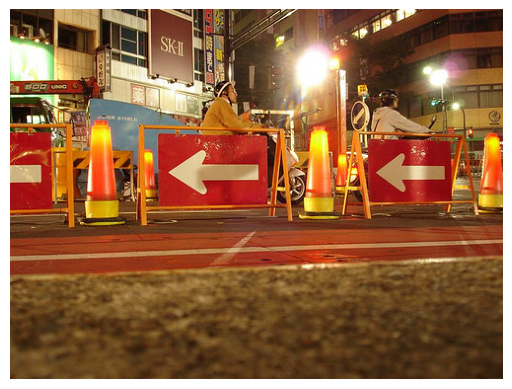

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.621 
['Construction signs and lights help those in traffic find the correct detour.', 'Construction workers standing behind arrow road signs.', 'Two people on motorbikes are riding past construction.', 'People are driving scooters down the street at night.', 'Road construction arrows are pointing left.']


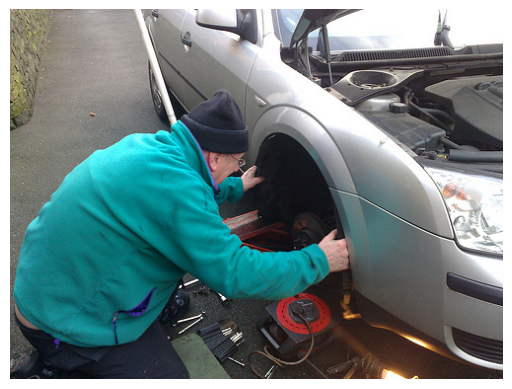

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.611 
['A man works on his car as he tries to keep warm with his hat and sweatshirt.', 'An elderly man in a light blue coat works on a car on the roadside.', 'Older man in a teal fleece jacket working on a car.', 'A man in a green jacket is working on his tire.', 'A man in a green jacket working on a car.']


In [40]:
nn_idx, dist = find_nn(text_prompt_embedding, image_embeddings, k=5)

print(f"{k} nearest neighbours: {nn_idx}")

for idx, d in zip(nn_idx, dist):
  #item = test_dataset[idx]
  img = test_dataset.dataset[idx]['image']
  plt.imshow(img)
  plt.axis("off")
  plt.show()
  print(f"Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: {d:0.3f} ")
  print(test_dataset.raw_captions[idx])

#6 Co dalej

Z uwagi na ograniczone zasoby obliczeniowe, wytrenowany w tym notatniku model `CLIPModel` ma ograniczoną skuteczność.
Oryginalny model CLIP był trenowany przez 12 dni przy wykorzystaniu 256 procesorów nVidia V100.

Do praktycznych zastosowań należy korzystać z gotowych pretrenowanych modeli dostępny w Internecie.
Warte uwagi są modele [OpenCLIP](https://github.com/mlfoundations/open_clip) dostępne w ramach otwartej licencji i wytrenowane na publicznie dostępnym zbiorze danych [LAION](https://laion.ai/).



*   Dokumentacja modelu CLIP w bibliotece HuggingFace i linki do przykładowych notatników: [link](https://huggingface.co/docs/transformers/model_doc/clip)
*   Przykład wykorzystania modelu OpenClip z biblioteki HuggingFace  w zadaniu klasyfikacji bez przykładów uczących (*zero-shot image classification*): [(link)](https://huggingface.co/docs/hub/open_clip)
*   Lista modeli z rodziny OpenCLIP dostępnych w bibliotece HuggingFace: [link](https://huggingface.co/models?library=open_clip&sort=trending)



